![ALT_TEXT_FOR_SCREEN_READERS](./header.png)

# Exercise 1 Wine Quality Regression

The aim of the example is to estimate the **quality of a wine** from physical measurands. To do this, we use different types of regression.
We use a dataset of wines from Portugal created by Paulo Cortez [1]. The details of the creation of the data can be found at the following link. [http://www3.dsi.uminho.pt/pcortez/wine5.pdf](http://www3.dsi.uminho.pt/pcortez/wine5.pdf). 

```
[1] P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis. 
  Modeling wine preferences by data mining from physicochemical properties.
  In Decision Support Systems, Elsevier, 47(4):547-553. ISSN: 0167-9236.
```

## Considerations

- Implement the exercise in **python** language
- Use the sklearn module of python
- You are allowed to use AI to support your work on the code
- You can implement the exercise in a local notebook or in a hosted colab notebook
- When you are using a local notebook, please create a copy of this notebook with a different name
- The code has to be included in the resulting print of the notebook
- Some results have to be documented and commented in the notebook in the table at the end of the notebook
- In order to support me finding the places where you fulfill the requirements. Please **mark** the code parts that related to a requirement with the **Rx** mark. E.g. **R0 near the download code**.

## Requirements

- R0: Search and download dataset to your drive
- R1: Import the data into memory using pandas read_csv (10%)
- R2: Display a sample of the data and the data shapes (5%)
- R3: Separate the features from the labels (quality) (10%)
- R4: Split the data into training data (70%) and test data (30%) (10%)
- R5: Train a linear regression model as the baseline model (10%)
- R6: Use the RMSE error measure to test the quality (10%)
- R7: Train and measure the quality of a random forest tree regression (10%)
- R8: Train and measure the quality of a gradient boosting regression, e.g. `GradientBoostingRegressor` (10%)
- R9: Train and measure the quality of a neural network (10%) 
- R10: Print the distribution of residuals (errors) over the test dataset (10%)
- R11: Special task: The random forest clearly beats the linear regression. Check whether this advantage holds for wines the model has never seen. If not, find the cause in the data, fix the evaluation and report the honest RMSE of both models (5%)


# Implementation

Head of the Dataset
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  


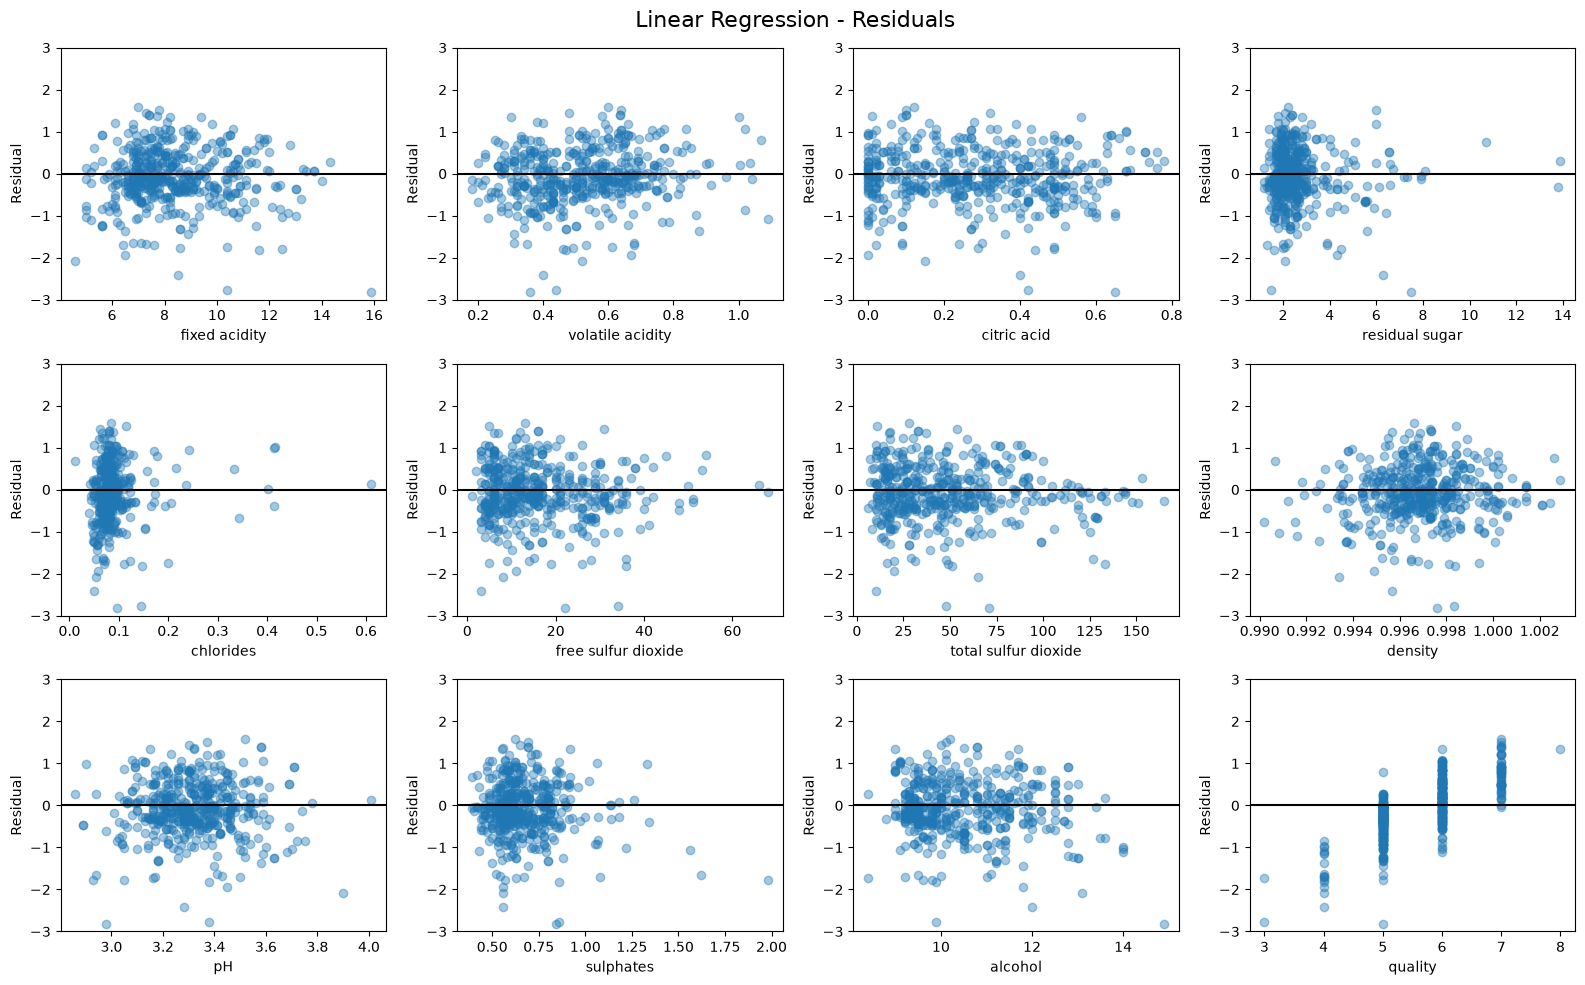

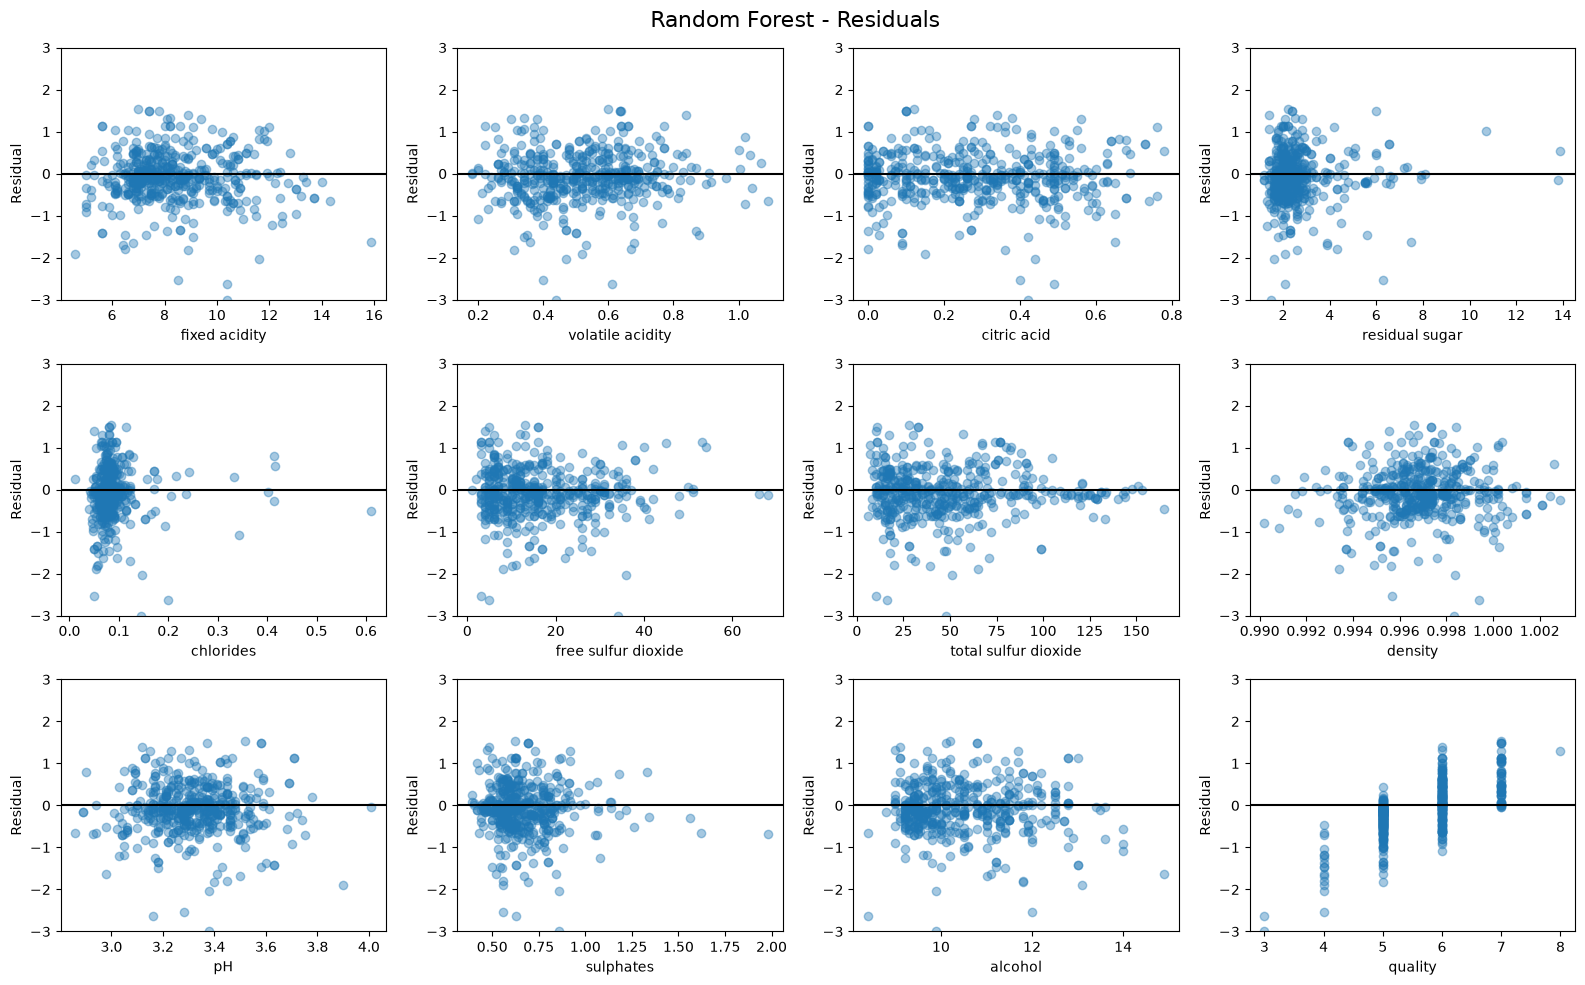

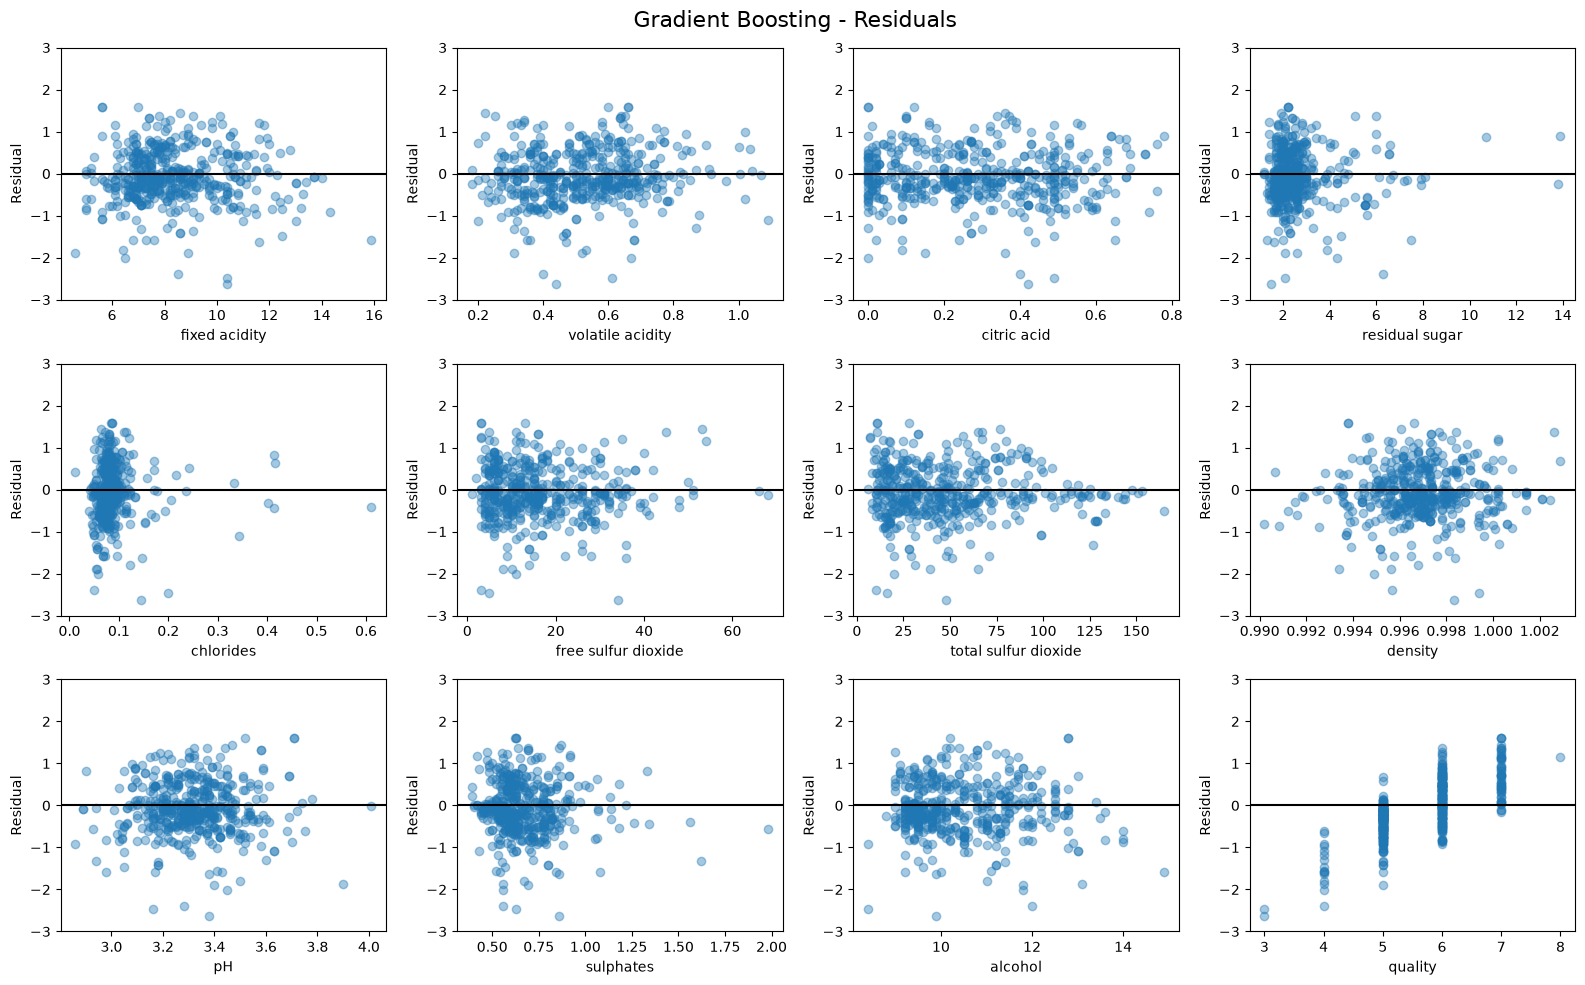

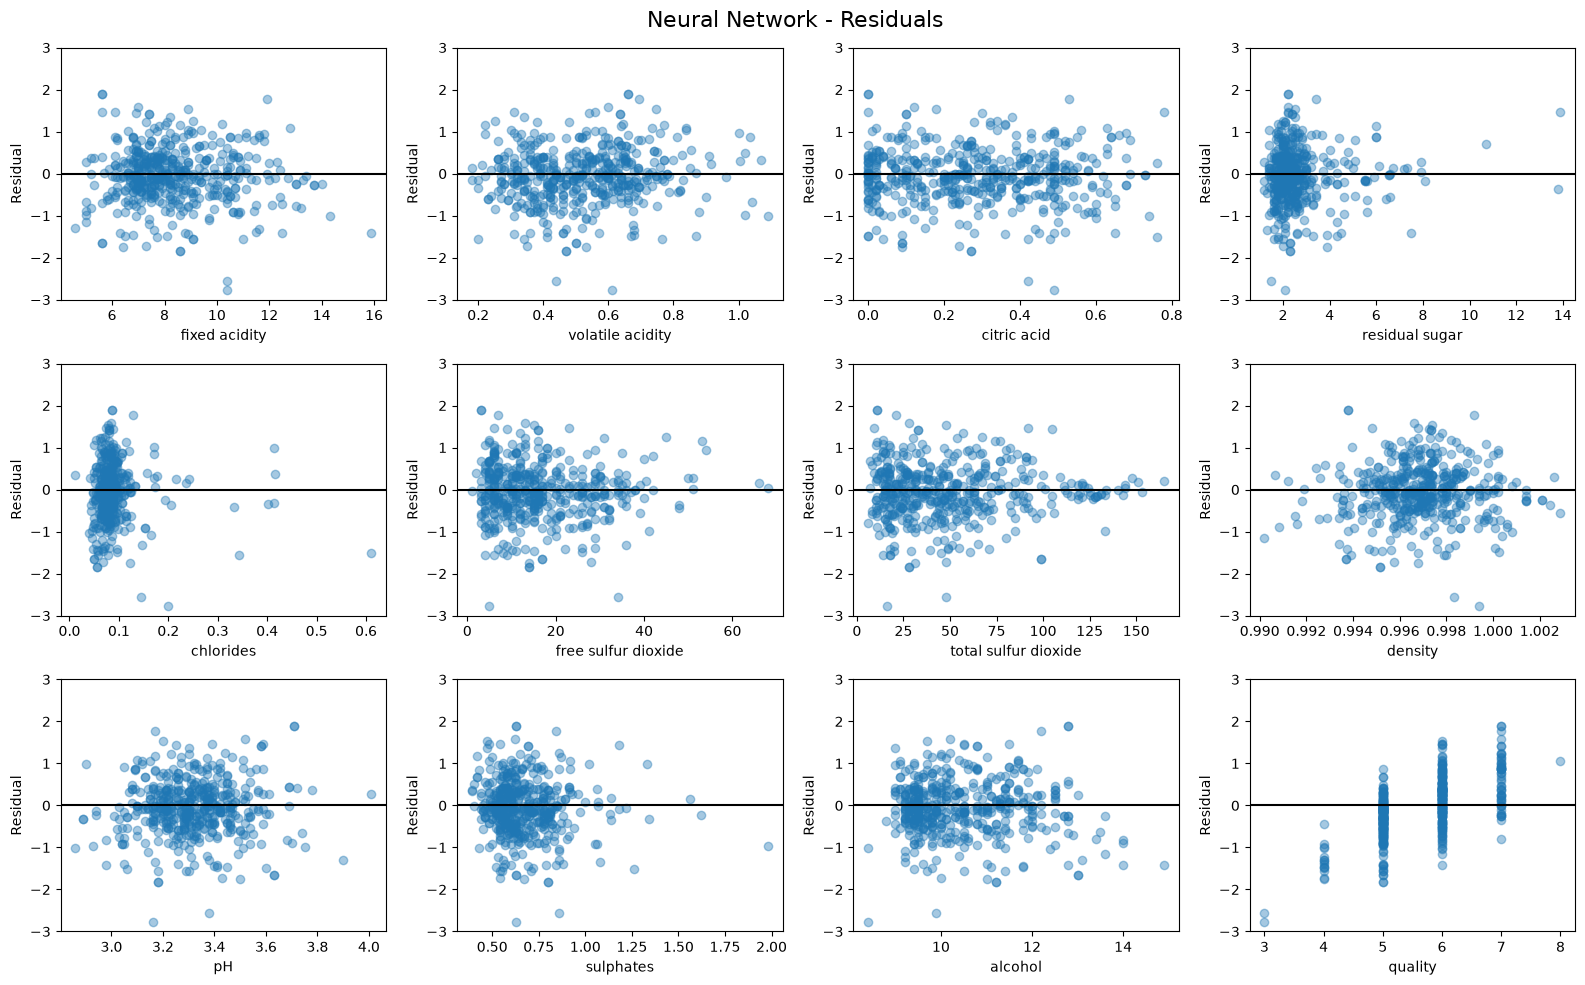

Training samples: 1119
Test samples: 480
Duplicates between train and test: 92
Percentage of test data: 19.166666666666668 %


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.3,0.48,0.32,2.1,0.062,31.0,54.0,0.99728,3.30,0.65,10.0
1,7.7,0.43,0.25,2.6,0.073,29.0,63.0,0.99615,3.37,0.58,10.5
2,6.8,0.64,0.00,2.7,0.123,15.0,33.0,0.99538,3.44,0.63,11.3
3,7.0,0.69,0.07,2.5,0.091,15.0,21.0,0.99572,3.38,0.60,11.3
4,6.8,0.65,0.02,2.1,0.078,8.0,15.0,0.99498,3.35,0.62,10.4
5,7.9,0.58,0.23,2.3,0.076,23.0,94.0,0.99686,3.21,0.58,9.5
6,7.8,0.53,0.01,1.6,0.077,3.0,19.0,0.99500,3.16,0.46,9.8
7,6.6,0.61,0.01,1.9,0.080,8.0,25.0,0.99746,3.69,0.73,10.5
8,8.8,0.30,0.38,2.3,0.060,19.0,72.0,0.99543,3.39,0.72,11.8
9,7.6,0.49,0.33,1.9,0.074,27.0,85.0,0.99706,3.41,0.58,9.0


Original test samples: 480
Duplicates removed: 92
Remaining test samples: 388
Linear Regression RMSE: 0.6797471620992622
Random Forest RMSE: 0.6690041067477545


In [7]:
# R0 the dataset is already in side the repo under /data

# R1 - Load dataset
import pandas as pd

df = pd.read_csv("data/winequality-red.csv", sep=",")

# R2 Display a datasample
print("Head of the Dataset")
print(df.head());
print("Shape of the data")
print(df.shape)

# R3 Separete the features and labels
# x are the input values
x = df.drop(columns=["quality"])
print("Input Data without the quality")
print(x.head())

y = df["quality"]
print("Expexted Output data, aka Quality")
print(y.head())

# R4 Split Training Data from Test Data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3)

# R5 Train a linear Regression Model

from sklearn.linear_model import LinearRegression

# Create a linear model and train it on the Training data
linear_model = LinearRegression();
linear_model.fit(x_train,y_train);

# Create a predicted Output from the model
y_pred_linear = linear_model.predict(x_test);


# R6 Calculate RMSE
import numpy as np

from sklearn.metrics import mean_squared_error

rmse_linear = np.sqrt(mean_squared_error(y_test,y_pred_linear))

print("\nLinear Regression RMSE:", rmse_linear)

# R7 Random forest regression
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor()
rf_model.fit(x_train,y_train)
y_pred_rf = rf_model.predict(x_test)

rmse_rf = np.sqrt(mean_squared_error(y_test,y_pred_rf))
print("Random Forest RMSE:",rmse_rf)

# R8 Gradient bossting regression

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor()

gb_model.fit(x_train, y_train)

y_pred_gb = gb_model.predict(x_test)

rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))

print("Gradient Boosting RMSE:", rmse_gb)


# R9 - Neural network regression

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

nn_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        max_iter=2000
    )
)

nn_model.fit(x_train, y_train)

y_pred_nn = nn_model.predict(x_test)

rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))

print("Neural Network RMSE:", rmse_nn)


# R10 Investigate the prediction errors
import matplotlib.pyplot as plt

models = {
    "Linear Regression": y_pred_linear,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "Neural Network": y_pred_nn
}

for name, predictions in models.items():

    residuals = y_test - predictions

    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    fig.suptitle(name + " - Residuals", fontsize=16)

    # All 11 input features + output quality
    features = list(x_test.columns) + ["quality"]

    for i, feature in enumerate(features):
        ax = axes.flat[i]

        if feature == "quality":
            x_values = y_test
        else:
            x_values = x_test[feature]

        ax.scatter(x_values, residuals, alpha=0.4)
        ax.axhline(0, color="black")

        ax.set_xlabel(feature)
        ax.set_ylabel("Residual")
        ax.set_ylim(-3, 3)

    plt.tight_layout()
    plt.show()


# Find test samples that also exist in the training data
duplicates = x_test.merge(
    x_train.drop_duplicates(),
    how="inner",
    on=list(x_train.columns)
)

print("Training samples:", len(x_train))
print("Test samples:", len(x_test))
print("Duplicates between train and test:", len(duplicates))
print("Percentage of test data:", len(duplicates) / len(x_test) * 100, "%")

display(duplicates.head(10))

# Remove duplicates from the testdata
# Find test samples that also occur in training data
duplicates = pd.MultiIndex.from_frame(x_test).isin(
    pd.MultiIndex.from_frame(x_train)
)

# Remove duplicated samples
x_test_clean = x_test.loc[~duplicates]
y_test_clean = y_test.loc[~duplicates]

print("Original test samples:", len(x_test))
print("Duplicates removed:", duplicates.sum())
print("Remaining test samples:", len(x_test_clean))


y_pred_linear_clean = linear_model.predict(x_test_clean)
y_pred_rf_clean = rf_model.predict(x_test_clean)

print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test_clean, y_pred_linear_clean)))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test_clean, y_pred_rf_clean)))


# Results

| Requirement  | RMSE  | Comment | 
|---|---|---|
| R6 linear regression | 0.64 |   |
| R7 random forest | 0.583  |   | 
| R8 gradient boosting | 0.616 |   | 
| R9 neural network | 0.665 |   | 
| R10 residuals | – | see Plots above. The residuals are spread acrous the Quality range, there is no tendance to over or under estimate certain wine based on their chemical properties but there is a tendance to under estimate high quality wine und over estimate low quality wine  | 
| R11 honest RMSE: linear regression / random forest | 0.679 LR / 0.669 RF  | There are duplicates that occur in the training data and also in the testdata! Now Linear Regression beats Random Forest  | 

